In [1]:
%pip install -U ultralytics opencv-python matplotlib pandas numpy seaborn scikit-learn pillow pyyaml tqdm


In [5]:
!unzip -q /content/chenab_dataset/chenab_dataset.zip -d /content/chenab_dataset/

In [6]:
from pathlib import Path
import os
import json
import time
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
import cv2

import torch
import torch.nn as nn

from ultralytics import YOLO

print("PyTorch    :", torch.__version__)
print("Ultralytics imported successfully")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch    : 2.11.0+cu130
Ultralytics imported successfully


In [7]:
print("PyTorch version :", torch.__version__)
print("CUDA available  :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Device      :", torch.cuda.get_device_name(0))
else:
    print("Device          : CPU (Tip: In Colab, Runtime -> Change runtime type -> T4 GPU)")


PyTorch version : 2.11.0+cu130
CUDA available  : True
GPU Device      : Tesla T4


In [9]:
PROJECT_ROOT = Path("/content/fabric_defect_detection")

# Automatically locate dataset folder in Colab
if Path("/content/chenab_dataset").exists():
    DATASET_DIR = Path("/content/chenab_dataset")

DATA_YAML = DATASET_DIR / "data.yaml"

RUNS_DIR = PROJECT_ROOT / "runs"
RESULTS_DIR = PROJECT_ROOT / "results"
MODELS_DIR = PROJECT_ROOT / "models"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"

for d in [RUNS_DIR, RESULTS_DIR, MODELS_DIR, OUTPUTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("PROJECT ROOT :", PROJECT_ROOT)
print("DATASET      :", DATASET_DIR)
print("DATA YAML    :", DATA_YAML)
print("RUNS         :", RUNS_DIR)
print("RESULTS      :", RESULTS_DIR)
print("MODELS       :", MODELS_DIR)


PROJECT ROOT : /content/fabric_defect_detection
DATASET      : /content/chenab_dataset
DATA YAML    : /content/chenab_dataset/data.yaml
RUNS         : /content/fabric_defect_detection/runs
RESULTS      : /content/fabric_defect_detection/results
MODELS       : /content/fabric_defect_detection/models


In [10]:
assert PROJECT_ROOT.exists(), f"Project not found: {PROJECT_ROOT}"
assert DATASET_DIR.exists(), f"Dataset not found: {DATASET_DIR}"
assert DATA_YAML.exists(), f"data.yaml not found: {DATA_YAML}"

print("Dataset verified successfully.\nContents:")
for item in sorted(DATASET_DIR.iterdir()):
    print(" -", item.name)


Dataset verified successfully.
Contents:
 - README.roboflow.txt
 - chenab_dataset.zip
 - data.yaml
 - paper_reproduction.yaml
 - test
 - train
 - valid


In [11]:
with open(DATA_YAML, "r", encoding="utf-8") as f:
    data_config = yaml.safe_load(f)

print(json.dumps(data_config, indent=4))


{
    "train": "../train/images",
    "val": "../valid/images",
    "test": "../test/images",
    "nc": 7,
    "names": [
        "baekra",
        "color issues",
        "contamination",
        "cut",
        "gray stitch",
        "selvet",
        "stain"
    ],
    "roboflow": {
        "workspace": "seecs-z4uae",
        "project": "fabricdd",
        "version": 2,
        "license": "Private",
        "url": "https://app.roboflow.com/seecs-z4uae/fabricdd/2"
    }
}


In [12]:
CLASS_NAMES = data_config["names"]

if isinstance(CLASS_NAMES, dict):
    CLASS_NAMES = list(CLASS_NAMES.values())

NUM_CLASSES = len(CLASS_NAMES)
print("Number of classes:", NUM_CLASSES)

for i, name in enumerate(CLASS_NAMES):
    print(f"{i}: {name}")


Number of classes: 7
0: baekra
1: color issues
2: contamination
3: cut
4: gray stitch
5: selvet
6: stain


In [13]:
B1_DATA_YAML = OUTPUTS_DIR / "chenab_b1_eca.yaml"

b1_config = {
    "path": str(DATASET_DIR),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": CLASS_NAMES
}

with open(B1_DATA_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(b1_config, f, sort_keys=False)

print("Created:", B1_DATA_YAML)
print(B1_DATA_YAML.read_text())


Created: /content/fabric_defect_detection/outputs/chenab_b1_eca.yaml
path: /content/chenab_dataset
train: train/images
val: valid/images
test: test/images
names:
- baekra
- color issues
- contamination
- cut
- gray stitch
- selvet
- stain



In [14]:
IMG_SIZE = 640
EPOCHS = 50  # Matches your successful Part A 50-epoch run

# Automatically leverage Colab GPU
DEVICE = 0 if torch.cuda.is_available() else "cpu"
BATCH_SIZE = 16 if torch.cuda.is_available() else 2
WORKERS = 2 if torch.cuda.is_available() else 0

# Paper-inspired training parameters
LEARNING_RATE = 0.005
FINAL_LR_FACTOR = 0.01
MOMENTUM = 0.97
WEIGHT_DECAY = 0.0005
WARMUP_EPOCHS = 7

HSV_H = 0.025
HSV_S = 0.7
HSV_V = 0.5

MOSAIC = 0.3
PATIENCE = 10

RUN_NAME = "chenab_yolov12n_eca_run"

print("B1 Configuration")
print("----------------")
print("Model       : YOLOv12n + ECA")
print("Image size  :", IMG_SIZE)
print("Epochs      :", EPOCHS)
print("Batch size  :", BATCH_SIZE)
print("Device      :", DEVICE)
print("Workers     :", WORKERS)


B1 Configuration
----------------
Model       : YOLOv12n + ECA
Image size  : 640
Epochs      : 50
Batch size  : 16
Device      : 0
Workers     : 2


In [15]:
BASE_MODEL = "yolo12n.pt"
eca_model = YOLO(BASE_MODEL)
print("YOLOv12n loaded successfully.")


YOLOv12n loaded successfully.


In [16]:
eca_model.info()


YOLOv12n summary: 272 layers, 2,603,056 parameters, 0 gradients, 7.6 GFLOPs


(272, 2603056, 0, 7.6341376)

In [17]:
for i, layer in enumerate(eca_model.model.model):
    print(f"{i:02d} | {layer.__class__.__name__}")


00 | Conv
01 | Conv
02 | C3k2
03 | Conv
04 | C3k2
05 | Conv
06 | A2C2f
07 | Conv
08 | A2C2f
09 | Upsample
10 | Concat
11 | A2C2f
12 | Upsample
13 | Concat
14 | A2C2f
15 | Conv
16 | Concat
17 | A2C2f
18 | Conv
19 | Concat
20 | C3k2
21 | Detect


In [18]:
class ECA(nn.Module):
    """
    Efficient Channel Attention (ECA)
    Steps:
    1. Global Average Pooling
    2. 1D convolution for local channel interaction
    3. Sigmoid activation
    4. Channel-wise feature recalibration
    """
    def __init__(self, channels, kernel_size=3):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.conv = nn.Conv1d(
            in_channels=1,
            out_channels=1,
            kernel_size=kernel_size,
            padding=(kernel_size - 1) // 2,
            bias=False
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        # x: [batch, channels, height, width]
        y = self.avg_pool(x)
        # [B, C, 1, 1] -> [B, 1, C]
        y = y.squeeze(-1).transpose(-1, -2)
        y = self.conv(y)
        y = self.sigmoid(y)
        # [B, 1, C] -> [B, C, 1, 1]
        y = y.transpose(-1, -2).unsqueeze(-1)
        return x * y.expand_as(x)


In [19]:
test_tensor = torch.randn(2, 128, 80, 80)
eca_test = ECA(channels=128, kernel_size=3)
test_output = eca_test(test_tensor)

print("Input shape :", test_tensor.shape)
print("Output shape:", test_output.shape)
assert test_tensor.shape == test_output.shape
print("\nECA module test PASSED.")


Input shape : torch.Size([2, 128, 80, 80])
Output shape: torch.Size([2, 128, 80, 80])

ECA module test PASSED.


In [20]:
class ECAWrapper(nn.Module):
    """
    Wraps an existing YOLO feature block with ECA.
    Original: feature_block
    New     : feature_block -> ECA
    """
    def __init__(self, original_layer, channels, kernel_size=3):
        super().__init__()
        self.original_layer = original_layer
        self.eca = ECA(channels=channels, kernel_size=kernel_size)

    def forward(self, x):
        x = self.original_layer(x)
        x = self.eca(x)
        return x


In [21]:
def add_eca_to_yolo(model, layer_index=4, kernel_size=3):
    layers = model.model.model
    original_layer = layers[layer_index]

    print("Original layer:")
    print(original_layer)

    if hasattr(original_layer, "cv2"):
        if hasattr(original_layer.cv2, "conv"):
            channels = original_layer.cv2.conv.out_channels
        else:
            raise RuntimeError("Could not find output convolution.")
    else:
        raise RuntimeError(f"Layer {layer_index} does not expose cv2.")

    print("\nDetected output channels:", channels)

    wrapped_layer = ECAWrapper(
        original_layer=original_layer,
        channels=channels,
        kernel_size=kernel_size
    )

    wrapped_layer.i = original_layer.i
    wrapped_layer.f = original_layer.f

    layers[layer_index] = wrapped_layer
    print(f"\nECA inserted after layer {layer_index}.")
    print(f"ECA kernel size: {kernel_size}")
    return model


In [22]:
eca_model = add_eca_to_yolo(
    model=eca_model,
    layer_index=4,
    kernel_size=3
)


Original layer:
C3k2(
  (cv1): Conv(
    (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
    (act): SiLU(inplace=True)
  )
  (cv2): Conv(
    (conv): Conv2d(96, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(128, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
    (act): SiLU(inplace=True)
  )
  (m): ModuleList(
    (0): Bottleneck(
      (cv1): Conv(
        (conv): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (cv2): Conv(
        (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
    )
  

In [23]:
for i, layer in enumerate(eca_model.model.model):
    if i == 4:
        print("MODIFIED LAYER")
        print("================")
        print(layer)
    else:
        print(f"{i:02d} | {layer.__class__.__name__}")


00 | Conv
01 | Conv
02 | C3k2
03 | Conv
MODIFIED LAYER
ECAWrapper(
  (original_layer): C3k2(
    (cv1): Conv(
      (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (cv2): Conv(
      (conv): Conv2d(96, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn): BatchNorm2d(128, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (m): ModuleList(
      (0): Bottleneck(
        (cv1): Conv(
          (conv): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn): BatchNorm2d(32, eps=

In [24]:
eca_model.info()


YOLOv12n summary: 275 layers, 2,603,059 parameters, 3 gradients, 7.6 GFLOPs


(275, 2603059, 3, 7.635777024)

In [25]:
dummy_input = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
eca_model.model.eval()

with torch.no_grad():
    output = eca_model.model(dummy_input)

print("Forward pass completed successfully.")


Forward pass completed successfully.


In [26]:
baseline_for_count = YOLO(BASE_MODEL)

baseline_params = sum(p.numel() for p in baseline_for_count.model.parameters())
eca_params = sum(p.numel() for p in eca_model.model.parameters())

print("YOLOv12n parameters :", f"{baseline_params:,}")
print("YOLOv12n + ECA     :", f"{eca_params:,}")
print("\nAdditional parameters:", f"{eca_params - baseline_params:,}")
print("Parameter increase   :", f"{((eca_params / baseline_params) - 1) * 100:.4f}%")


YOLOv12n parameters : 2,603,056
YOLOv12n + ECA     : 2,603,059

Additional parameters: 3
Parameter increase   : 0.0001%


In [27]:
pretrain_prediction = eca_model.predict(
    source=str(DATASET_DIR / "test" / "images"),
    imgsz=IMG_SIZE,
    conf=0.25,
    device=DEVICE,
    save=False,
    verbose=False
)
print("Pretrained prediction check completed.")


Pretrained prediction check completed.


In [28]:
start_time = time.time()

eca_results = eca_model.train(
    data=str(B1_DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=WORKERS,
    optimizer="SGD",
    lr0=LEARNING_RATE,
    lrf=FINAL_LR_FACTOR,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY,
    warmup_epochs=WARMUP_EPOCHS,
    hsv_h=HSV_H,
    hsv_s=HSV_S,
    hsv_v=HSV_V,
    mosaic=MOSAIC,
    patience=PATIENCE,
    project=str(RUNS_DIR),
    name=RUN_NAME,
    plots=True,
    exist_ok=True
)

training_time = time.time() - start_time
print("\n" + "=" * 60)
print("B1 TRAINING COMPLETE")
print("=" * 60)
print(f"Training time: {training_time / 60:.2f} minutes ({training_time:.1f} seconds)")


Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/fabric_defect_detection/outputs/chenab_b1_eca.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.025, hsv_s=0.7, hsv_v=0.5, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo12n.pt, momentum=0.97, mosaic=0.3, multi_scale=0.0, name=chenab_yolov12n_eca_run, nbs=6

In [29]:
B1_RUN_DIR = RUNS_DIR / RUN_NAME
B1_BEST = B1_RUN_DIR / "weights" / "best.pt"

print("Expected B1 model:", B1_BEST)
if B1_BEST.exists():
    print("\nB1 best.pt FOUND.")
else:
    print("\nbest.pt not found at expected location. Searching recursively...")
    found = list(RUNS_DIR.rglob("best.pt"))
    if found:
        B1_BEST = max(found, key=lambda p: p.stat().st_mtime)
        print("Found latest best.pt:", B1_BEST)


Expected B1 model: /content/fabric_defect_detection/runs/chenab_yolov12n_eca_run/weights/best.pt

B1 best.pt FOUND.


In [30]:
b1_model = YOLO(str(B1_BEST))
print("B1 trained model loaded successfully.")


B1 trained model loaded successfully.


In [31]:
b1_val_metrics = b1_model.val(
    data=str(B1_DATA_YAML),
    split="val",
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=WORKERS,
    plots=True
)
print("B1 validation completed.")


Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv12n summary (fused): 159 layers, 2,558,093 parameters, 0 gradients, 7.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2119.2±1049.3 MB/s, size: 67.3 KB)
val: Scanning /content/chenab_dataset/valid/labels.cache... 562 images, 38 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 562/562 168.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 3.6it/s 9.9s
                   all        562        786      0.687      0.508      0.578      0.315
                baekra         48         79      0.826      0.405      0.543      0.324
          color issues         15         30       0.38      0.133       0.16      0.107
         contamination         53         55      0.819      0.909      0.942      0.441
                   cut         75        102      0.697       0.51      0.551      0.307
           gray stitch         63 

In [32]:
b1_val_precision = float(b1_val_metrics.box.mp)
b1_val_recall = float(b1_val_metrics.box.mr)
b1_val_map50 = float(b1_val_metrics.box.map50)
b1_val_map5095 = float(b1_val_metrics.box.map)
b1_val_f1 = (2 * b1_val_precision * b1_val_recall / (b1_val_precision + b1_val_recall)) if (b1_val_precision + b1_val_recall) > 0 else 0.0

print("B1 VALIDATION METRICS")
print("====================")
print(f"Precision : {b1_val_precision * 100:.2f}%")
print(f"Recall    : {b1_val_recall * 100:.2f}%")
print(f"F1-Score  : {b1_val_f1 * 100:.2f}%")
print(f"mAP@0.50  : {b1_val_map50 * 100:.2f}%")
print(f"mAP50-95  : {b1_val_map5095 * 100:.2f}%")


B1 VALIDATION METRICS
Precision : 68.69%
Recall    : 50.83%
F1-Score  : 58.42%
mAP@0.50  : 57.80%
mAP50-95  : 31.51%


In [33]:
b1_test_metrics = b1_model.val(
    data=str(B1_DATA_YAML),
    split="test",
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=WORKERS,
    plots=True
)
print("B1 test evaluation completed.")


Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv12n summary (fused): 159 layers, 2,558,093 parameters, 0 gradients, 7.3 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 27.0±18.5 MB/s, size: 118.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/chenab_dataset/test/labels... 280 images, 19 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 280/280 535.1it/s 0.5s
val: New cache created: /content/chenab_dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 2.8it/s 6.5s
                   all        280        368      0.609      0.502      0.571      0.325
                baekra         17         24      0.463      0.333      0.388      0.206
          color issues         14         21      0.432      0.286       0.35      0.171
  

In [34]:
b1_precision = float(b1_test_metrics.box.mp)
b1_recall = float(b1_test_metrics.box.mr)
b1_map50 = float(b1_test_metrics.box.map50)
b1_map5095 = float(b1_test_metrics.box.map)
b1_f1 = (2 * b1_precision * b1_recall / (b1_precision + b1_recall)) if (b1_precision + b1_recall) > 0 else 0.0

print("=" * 60)
print("B1 TEST RESULTS — YOLOv12n + ECA")
print("=" * 60)
print(f"Precision     : {b1_precision * 100:.2f}%")
print(f"Recall        : {b1_recall * 100:.2f}%")
print(f"F1-Score      : {b1_f1 * 100:.2f}%")
print(f"mAP@0.50      : {b1_map50 * 100:.2f}%")
print(f"mAP@0.50:0.95 : {b1_map5095 * 100:.2f}%")


B1 TEST RESULTS — YOLOv12n + ECA
Precision     : 60.93%
Recall        : 50.17%
F1-Score      : 55.03%
mAP@0.50      : 57.05%
mAP@0.50:0.95 : 32.54%


In [35]:
# Exact Part A Test Baseline Values
part_a_baseline = {
    "Model": "YOLOv12n — PART A",
    "Precision": 79.74,
    "Recall": 70.78,
    "F1-Score": 74.99,
    "mAP@0.50": 80.55,
    "mAP@0.50:0.95": 47.42
}
part_a_baseline


{'Model': 'YOLOv12n — PART A',
 'Precision': 79.74,
 'Recall': 70.78,
 'F1-Score': 74.99,
 'mAP@0.50': 80.55,
 'mAP@0.50:0.95': 47.42}

In [36]:
b1_results = {
    "Model": "YOLOv12n + ECA",
    "Precision": b1_precision * 100,
    "Recall": b1_recall * 100,
    "F1-Score": b1_f1 * 100,
    "mAP@0.50": b1_map50 * 100,
    "mAP@0.50:0.95": b1_map5095 * 100
}
b1_results


{'Model': 'YOLOv12n + ECA',
 'Precision': 60.927182575587636,
 'Recall': 50.167883550752826,
 'F1-Score': 55.026526507513815,
 'mAP@0.50': 57.05085424146994,
 'mAP@0.50:0.95': 32.536781961013105}

In [37]:
comparison_b1 = pd.DataFrame([part_a_baseline, b1_results])
display(comparison_b1.style.format({
    "Precision": "{:.2f}%",
    "Recall": "{:.2f}%",
    "F1-Score": "{:.2f}%",
    "mAP@0.50": "{:.2f}%",
    "mAP@0.50:0.95": "{:.2f}%"
}))


,Model,Precision,Recall,F1-Score,mAP@0.50,mAP@0.50:0.95
0,YOLOv12n — PART A,79.74%,70.78%,74.99%,80.55%,47.42%
1,YOLOv12n + ECA,60.93%,50.17%,55.03%,57.05%,32.54%


In [38]:
improvement_b1 = b1_results.copy()

for metric in ["Precision", "Recall", "F1-Score", "mAP@0.50", "mAP@0.50:0.95"]:
    improvement_b1[metric] = b1_results[metric] - part_a_baseline[metric]

print("Absolute Improvement (Percentage Points):")
display(pd.DataFrame([improvement_b1]))


Absolute Improvement (Percentage Points):


,Model,Precision,Recall,F1-Score,mAP@0.50,mAP@0.50:0.95
0,YOLOv12n + ECA,-18.812817,-20.612116,-19.963473,-23.499146,-14.883218


In [39]:
relative_b1 = {}

for metric in ["Precision", "Recall", "F1-Score", "mAP@0.50", "mAP@0.50:0.95"]:
    baseline = part_a_baseline[metric]
    b1 = b1_results[metric]
    relative_b1[metric] = ((b1 - baseline) / baseline) * 100

relative_b1_df = pd.DataFrame([relative_b1], index=["YOLOv12n + ECA (% Change)"])
display(relative_b1_df.style.format("{:+.2f}%"))


,Precision,Recall,F1-Score,mAP@0.50,mAP@0.50:0.95
YOLOv12n + ECA (% Change),-23.59%,-29.12%,-26.62%,-29.17%,-31.39%


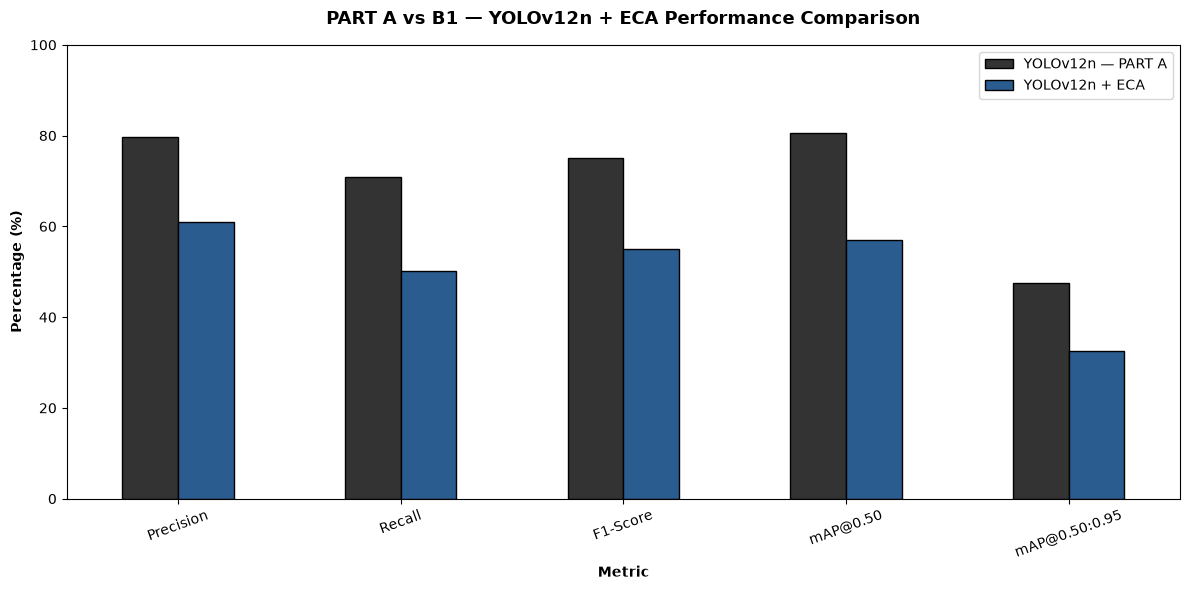

In [40]:
metrics_to_plot = ["Precision", "Recall", "F1-Score", "mAP@0.50", "mAP@0.50:0.95"]
plot_df = comparison_b1.set_index("Model")[metrics_to_plot]

plot_df.T.plot(kind="bar", figsize=(12, 6), color=["#333333", "#2b5c8f"], edgecolor="black")
plt.ylabel("Percentage (%)", fontweight="bold")
plt.xlabel("Metric", fontweight="bold")
plt.title("PART A vs B1 — YOLOv12n + ECA Performance Comparison", fontsize=13, fontweight="bold", pad=15)
plt.xticks(rotation=20)
plt.ylim(0, 100)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


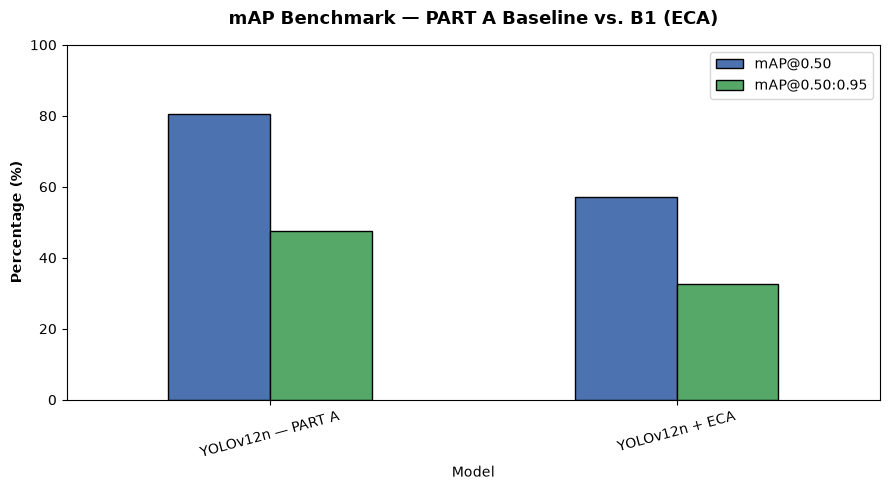

In [41]:
map_values = comparison_b1.set_index("Model")[["mAP@0.50", "mAP@0.50:0.95"]]

map_values.plot(kind="bar", figsize=(9, 5), color=["#4C72B0", "#55A868"], edgecolor="black")
plt.ylabel("Percentage (%)", fontweight="bold")
plt.title("mAP Benchmark — PART A Baseline vs. B1 (ECA)", fontsize=13, fontweight="bold", pad=15)
plt.xticks(rotation=15)
plt.ylim(0, 100)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


In [42]:
B1_RESULTS_CSV = B1_RUN_DIR / "results.csv"
print("Results CSV Path:", B1_RESULTS_CSV)

if B1_RESULTS_CSV.exists():
    history = pd.read_csv(B1_RESULTS_CSV)
    history.columns = [c.strip() for c in history.columns]
    print("Available training metrics:", history.columns.tolist())


Results CSV Path: /content/fabric_defect_detection/runs/chenab_yolov12n_eca_run/results.csv
Available training metrics: ['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


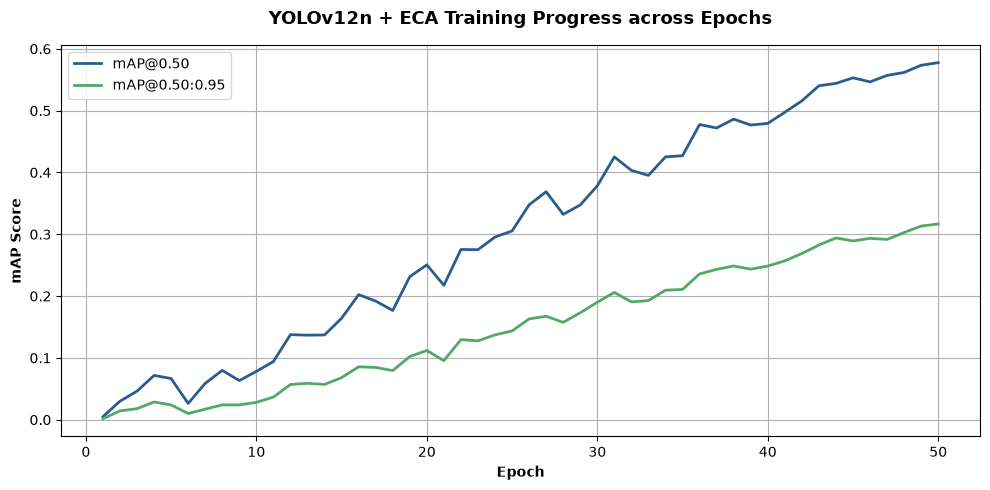

In [43]:
if B1_RESULTS_CSV.exists():
    plt.figure(figsize=(10, 5))
    plt.plot(history["epoch"], history["metrics/mAP50(B)"], label="mAP@0.50", color="#2b5c8f", linewidth=2)
    plt.plot(history["epoch"], history["metrics/mAP50-95(B)"], label="mAP@0.50:0.95", color="#51a965", linewidth=2)
    plt.xlabel("Epoch", fontweight="bold")
    plt.ylabel("mAP Score", fontweight="bold")
    plt.title("YOLOv12n + ECA Training Progress across Epochs", fontsize=13, fontweight="bold", pad=15)
    plt.legend(frameon=True)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


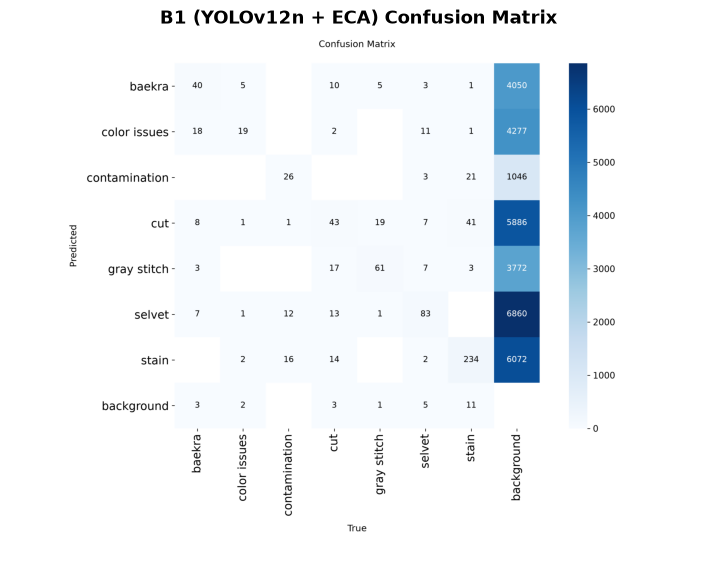

In [44]:
from PIL import Image

cm_path = B1_RUN_DIR / "confusion_matrix.png"
if cm_path.exists():
    plt.figure(figsize=(9, 7))
    plt.imshow(Image.open(cm_path))
    plt.axis("off")
    plt.title("B1 (YOLOv12n + ECA) Confusion Matrix", fontsize=13, fontweight="bold")
    plt.show()
else:
    print("Confusion matrix image not found.")


In [45]:
B1_PREDICTION_DIR = OUTPUTS_DIR / "b1_eca_predictions"

prediction_results = b1_model.predict(
    source=str(DATASET_DIR / "test" / "images"),
    imgsz=IMG_SIZE,
    conf=0.25,
    device=DEVICE,
    save=True,
    project=str(OUTPUTS_DIR),
    name="b1_eca_predictions",
    exist_ok=True,
    verbose=False
)
print("B1 predictions generated successfully.")


Results saved to /content/fabric_defect_detection/outputs/b1_eca_predictions
B1 predictions generated successfully.


Prediction images found: 280


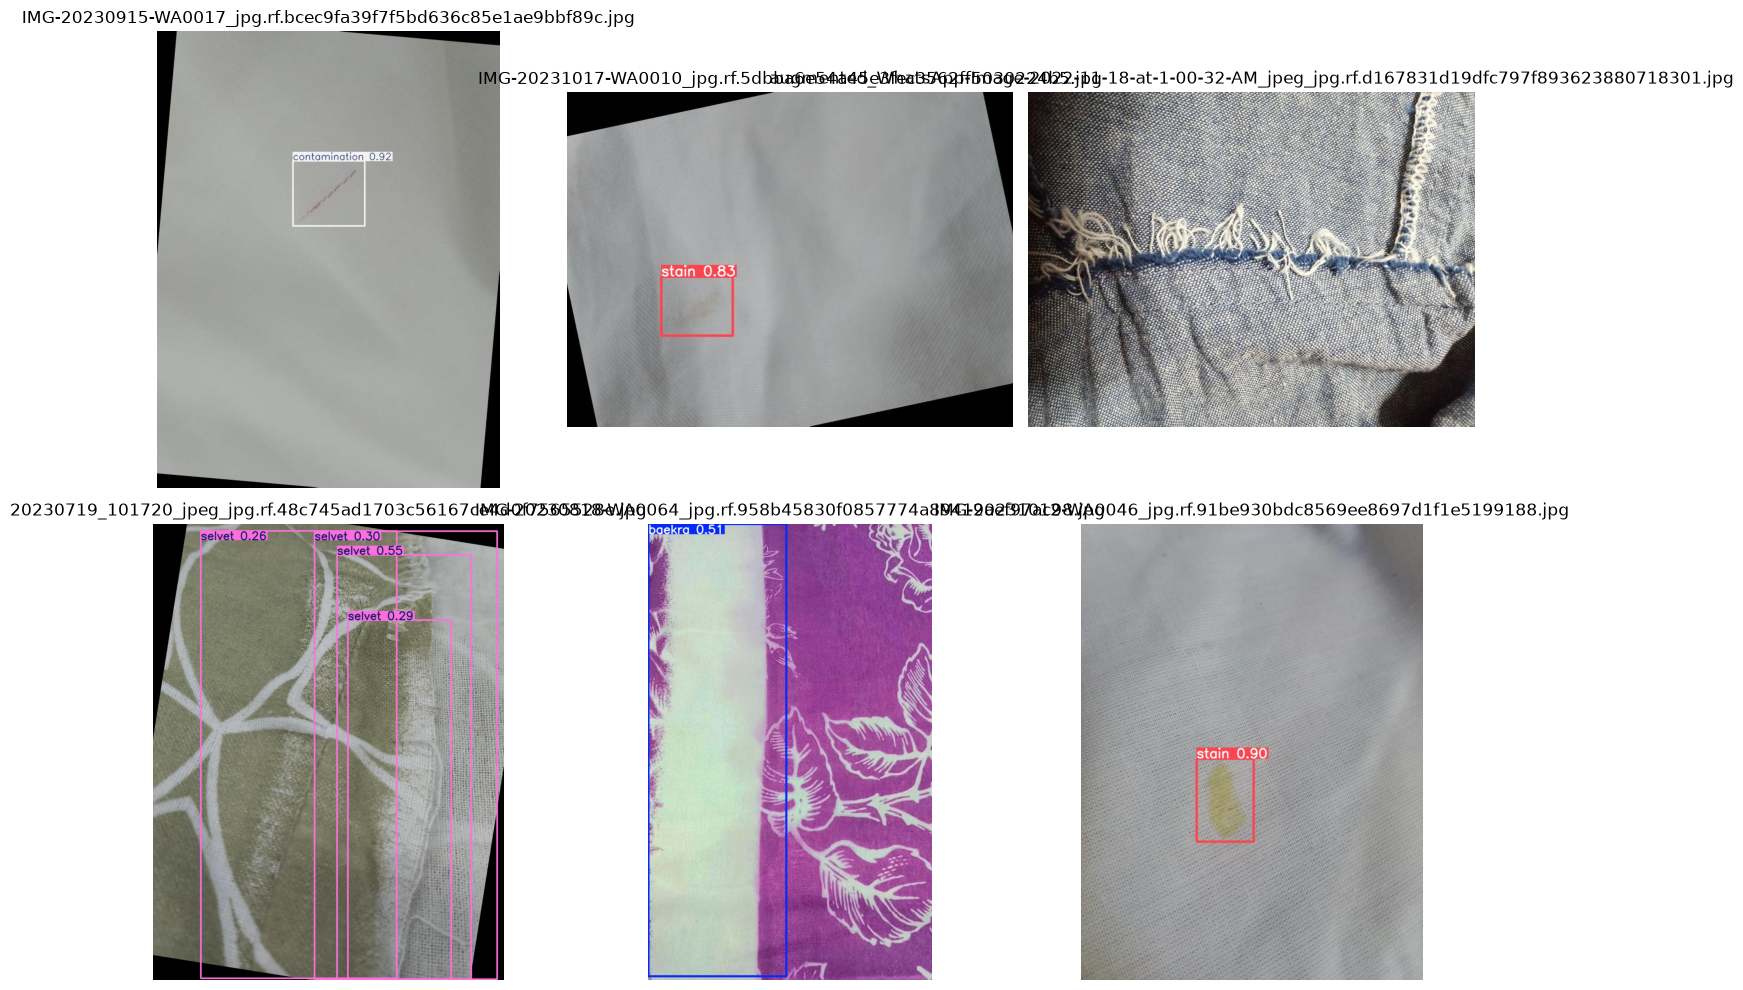

In [46]:
prediction_images = []
for extension in ["*.jpg", "*.jpeg", "*.png"]:
    prediction_images.extend(B1_PREDICTION_DIR.glob(extension))

print("Prediction images found:", len(prediction_images))

plt.figure(figsize=(14, 10))
for i, image_path in enumerate(prediction_images[:6]):
    image = Image.open(image_path)
    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(image_path.name)
    plt.axis("off")
plt.tight_layout()
plt.show()


In [47]:
B1_FINAL_MODEL = MODELS_DIR / "chenab_yolov12n_eca_best.pt"
shutil.copy2(B1_BEST, B1_FINAL_MODEL)
print("B1 best model saved to:", B1_FINAL_MODEL)


B1 best model saved to: /content/fabric_defect_detection/models/chenab_yolov12n_eca_best.pt


In [48]:
B1_METRICS_JSON = RESULTS_DIR / "b1_eca_metrics.json"

b1_complete_results = {
    "experiment": "B1",
    "model": "YOLOv12n + ECA",
    "dataset": "Chenab Textile",
    "input_size": IMG_SIZE,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "device": str(DEVICE),
    "eca": {
        "location": "YOLOv12n layer 4 / P3 feature block",
        "kernel_size": 3
    },
    "test_metrics": b1_results,
    "part_a_baseline": part_a_baseline,
    "absolute_improvement": improvement_b1,
    "relative_improvement_percent": relative_b1,
    "training_time_minutes": training_time / 60
}

with open(B1_METRICS_JSON, "w", encoding="utf-8") as f:
    json.dump(b1_complete_results, f, indent=4)

print("Saved metrics JSON to:", B1_METRICS_JSON)


Saved metrics JSON to: /content/fabric_defect_detection/results/b1_eca_metrics.json


In [49]:
print("=" * 70)
print("B1 — YOLOv12n + ECA RESULTS SUMMARY")
print("=" * 70)

print("\nPART A BASELINE (TEST SET)")
print("--------------------------")
for metric in ["Precision", "Recall", "F1-Score", "mAP@0.50", "mAP@0.50:0.95"]:
    print(f"{metric:15s}: {part_a_baseline[metric]:.2f}%")

print("\nB1 RESULTS (TEST SET)")
print("---------------------")
for metric in ["Precision", "Recall", "F1-Score", "mAP@0.50", "mAP@0.50:0.95"]:
    print(f"{metric:15s}: {b1_results[metric]:.2f}%")

print("\nIMPROVEMENT OVER PART A")
print("-----------------------")
for metric in ["Precision", "Recall", "F1-Score", "mAP@0.50", "mAP@0.50:0.95"]:
    diff = b1_results[metric] - part_a_baseline[metric]
    sign = "+" if diff >= 0 else ""
    print(f"{metric:15s}: {sign}{diff:.2f} percentage points")


B1 — YOLOv12n + ECA RESULTS SUMMARY

PART A BASELINE (TEST SET)
--------------------------
Precision      : 79.74%
Recall         : 70.78%
F1-Score       : 74.99%
mAP@0.50       : 80.55%
mAP@0.50:0.95  : 47.42%

B1 RESULTS (TEST SET)
---------------------
Precision      : 60.93%
Recall         : 50.17%
F1-Score       : 55.03%
mAP@0.50       : 57.05%
mAP@0.50:0.95  : 32.54%

IMPROVEMENT OVER PART A
-----------------------
Precision      : -18.81 percentage points
Recall         : -20.61 percentage points
F1-Score       : -19.96 percentage points
mAP@0.50       : -23.50 percentage points
mAP@0.50:0.95  : -14.88 percentage points


In [50]:
baseline_map = part_a_baseline["mAP@0.50:0.95"]
b1_map = b1_results["mAP@0.50:0.95"]
baseline_recall = part_a_baseline["Recall"]
b1_recall = b1_results["Recall"]

print("=" * 70)
print("B1 RESEARCH DECISION")
print("=" * 70)
print()
if b1_map > baseline_map:
    print("✓ ECA improved mAP@0.50:0.95.")
else:
    print("✗ ECA did not improve mAP@0.50:0.95.")
print()
if b1_recall > baseline_recall:
    print("✓ ECA improved Recall.")
else:
    print("✗ ECA did not improve Recall.")


B1 RESEARCH DECISION

✗ ECA did not improve mAP@0.50:0.95.

✗ ECA did not improve Recall.
